# 02 · Backtest L2 su FI-2010 (esperimenti E1 ed E2)

Con dati L2 non si sa se un proprio ordine è stato eseguito: si vede solo come cambiano i prezzi migliori. Bisogna quindi scegliere una **regola** che lo deduca. Qui la stessa strategia viene simulata sugli stessi dati con tre regole diverse:

| Regola | Un acquisto al prezzo *p* è considerato eseguito quando… | Carattere |
|---|---|---|
| `touch` (E1) | il miglior prezzo in acquisto è uguale o inferiore a *p* | ottimista: basta che il prezzo non salga |
| `price-through` (E2) | il miglior prezzo in acquisto scende sotto *p* | prudente: il livello della quota è stato svuotato |
| `cross` | il miglior prezzo in vendita scende fino a *p* | prudente: il lato opposto arriva alla quota |

FI-2010 non contiene i singoli ordini, quindi qui non esiste un "risultato vero" con cui confrontarsi: il confronto con la coda reale arriva nei notebook 04 e 05. I prezzi sono normalizzati: il P&L è in unità normalizzate e le commissioni non si possono applicare.

I termini tecnici sono spiegati nel **glossario** in fondo al notebook 06.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/market_making_tesi").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from market_making_tesi import report as R
from market_making_tesi.report import it, pct
R.setup_plots()
FIGURES = ROOT / "results" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
np.random.seed(0)
test = R.load(ROOT, "test")                      # sessioni di test, strategia selezionata
validation = R.load(ROOT, "validation")          # griglia di parametri sulle sessioni di validazione
ablation = R.load(ROOT, "ablation")              # test ripetuto senza filtro di volatilità
variants = R.load(ROOT, "variants")              # varianti: inventory skew e imbalance
selected = R.load_json(ROOT, "selected_params")  # parametri scelti in validazione

stats = R.model_table(test, "fi2010")
R.show_box("In breve", [
    f"Con `touch` la strategia guadagna in media {it(stats.loc['touch', 'media'], 3)} per sessione ed è positiva {R.nel(stats.loc['touch', 'quota_positive'], 0)} delle sessioni.",
    f"Con `price-through` il risultato è {it(stats.loc['price-through', 'media'], 4)} e con `cross` {it(stats.loc['cross', 'media'], 4)}.",
    "Cambiando solo la regola di esecuzione, la stessa strategia passa da profittevole a in perdita.",
])

> **In breve**
>
> - Con `touch` la strategia guadagna in media 0,371 per sessione ed è positiva nel 100% delle sessioni.
> - Con `price-through` il risultato è -0,0044 e con `cross` -0,0141.
> - Cambiando solo la regola di esecuzione, la stessa strategia passa da profittevole a in perdita.

## 1. Scelta dei parametri (validazione)

Sui giorni 2 e 3 si provano 12 combinazioni: due finestre di volatilità, tre soglie e due durate massime degli ordini. Si sceglie quella con il P&L medio più alto usando `price-through`, la regola prudente prevista dal piano. Più scuro = risultato migliore.

In [2]:
display(R.validation_grid(validation, "fi2010", "final_equity").style.format("{:.4f}").background_gradient(cmap="Greys", axis=None))
display(Markdown(f"**Parametri scelti:** {R.params_text('fi2010', selected['fi2010']['params'])}."))

**Parametri scelti:** volatilità su una finestra di 100 osservazioni; si opera solo sotto il 90° percentile della volatilità di calibrazione; ogni quota resta nel book al massimo 200 osservazioni.

## 2. Risultati sulle sessioni di test

35 sessioni (giorni 4-10, cinque titoli). Per ogni regola: P&L medio per sessione con intervallo di confidenza al 95% (calcolato con il bootstrap) e quota di sessioni chiuse in guadagno.

,P&L medio per sessione (IC 95%),sessioni positive,sessioni
touch,"0,3715 (0,2435; 0,5294)",100%,35
price-through,"-0,0044 (-0,0073; -0,0018)",20%,35
cross,"-0,0141 (-0,0184; -0,0102)",0%,35


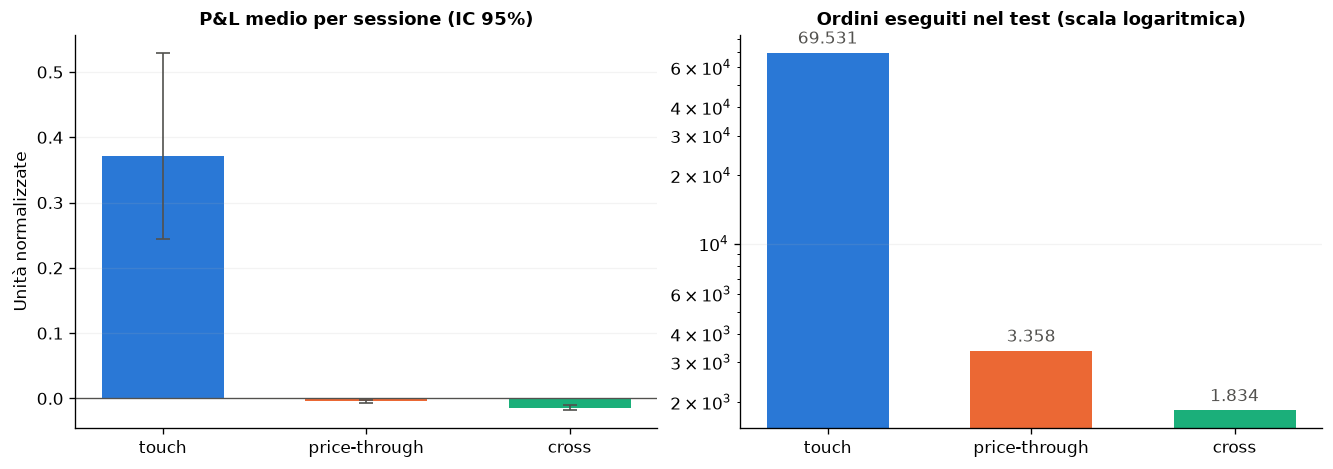

**Come leggerlo.** `touch` conta 38 volte le esecuzioni di `cross`. Quasi tutte le coppie si chiudono su entrambi i lati e la strategia incassa lo spread di continuo: un guadagno che nasce dalla regola, non dal mercato (vedi notebook 01, prezzo fermo).

In [3]:
display(R.results_table(stats, 4))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
R.bar_by_model(axes[0], stats, "P&L medio per sessione (IC 95%)", "Unità normalizzate")
fills = test[test.dataset == "fi2010"].groupby("model").maker_fills.sum().reindex(["touch", "price-through", "cross"])
axes[1].bar([R.LABELS[m] for m in fills.index], fills, color=[R.COLORS[m] for m in fills.index], width=0.6)
for k, v in enumerate(fills):
    axes[1].text(k, v * 1.1, it(v), ha="center", color=R.INK)
axes[1].set(yscale="log", title="Ordini eseguiti nel test (scala logaritmica)")
axes[1].grid(axis="x", visible=False)
fig.savefig(FIGURES / "fi2010_test.png", dpi=180, bbox_inches="tight")
plt.show()
display(Markdown(
    f"**Come leggerlo.** `touch` conta {it(fills['touch'] / fills['cross'])} volte le esecuzioni di `cross`. "
    "Quasi tutte le coppie si chiudono su entrambi i lati e la strategia incassa lo spread di continuo: un guadagno che "
    "nasce dalla regola, non dal mercato (vedi notebook 01, prezzo fermo)."))

## 3. Perché le regole danno risultati opposti

Ogni coppia di ordini può finire in tre modi: **entrambi i lati eseguiti** (si incassa lo spread), **un solo lato** (si resta con inventario e si chiude a mercato pagando lo spread) oppure **nessuno**. Il P&L si scompone in tre parti:

* **spread incassato (edge maker)**: quanto si guadagna rispetto al prezzo medio al momento dell'esecuzione;
* **costo di liquidazione**: quanto si paga per chiudere l'inventario a mercato;
* **movimento del prezzo sull'inventario**: guadagno o perdita mentre si detiene la posizione.

In [4]:
display(R.fill_rates_table(R.fill_rates(test, "fi2010")))
display(R.decomposition_table(R.decomposition(test, "fi2010"), 4))
display(Markdown(
    "**Come leggerlo.** Con `cross` lo spread incassato è negativo: la regola esegue la quota solo quando il prezzo l'ha "
    "già superata, cioè sempre a un prezzo peggiore del prezzo medio. Con `touch` succede il contrario. Nessuna delle due "
    "descrive cosa sarebbe successo davvero: per saperlo servono i singoli ordini (notebook 04)."))

,coppie quotate,entrambi i lati eseguiti,un solo lato eseguito,nessun lato eseguito,con fill parziale
touch,35.338,97%,3%,0%,0%
price-through,2.466,41%,53%,5%,0%
cross,1.958,17%,60%,23%,0%


,spread incassato (edge maker),costo di liquidazione,movimento del prezzo sull'inventario,= P&L lordo
touch,"0,3791","-0,0059","-0,0017","0,3715"
price-through,"0,0068","-0,0071","-0,0042","-0,0044"
cross,"-0,0074","-0,0060","-0,0007","-0,0141"


**Come leggerlo.** Con `cross` lo spread incassato è negativo: la regola esegue la quota solo quando il prezzo l'ha già superata, cioè sempre a un prezzo peggiore del prezzo medio. Con `touch` succede il contrario. Nessuna delle due descrive cosa sarebbe successo davvero: per saperlo servono i singoli ordini (notebook 04).

## 4. Il filtro di volatilità serve?

Le stesse sessioni di test sono ripetute con la strategia **sempre attiva** (senza filtro). La differenza è calcolata sessione per sessione: positiva = il filtro migliora il risultato.

In [5]:
effect = R.filter_effect(test, ablation, "fi2010", "final_equity")
display(R.filter_table(effect, 4))
pt = effect.loc["price-through"]
verdict = ("migliora" if pt["IC95 basso"] > 0 else "peggiora" if pt["IC95 alto"] < 0 else "non cambia in modo significativo")
display(Markdown(
    f"**Come leggerlo.** Su FI-2010, con la regola di riferimento `price-through`, il filtro {verdict} il risultato "
    f"(differenza {it(pt['differenza'], 4)}): la strategia opera {R.nel(pt['quota record attivi'], 0)} del tempo, ma "
    "fermarsi nei momenti agitati non evita le esecuzioni sfavorevoli quando il mercato è calmo."))

,con filtro,sempre attiva,differenza (IC 95%),sessioni migliori con filtro,tempo in cui opera
modello,,,,,
touch,"0,3715","0,3535","0,0179 (-0,0054; 0,0416)",63%,85%
price-through,"-0,0044","-0,0026","-0,0019 (-0,0033; -0,0004)",23%,85%
cross,"-0,0141","-0,0141","0,0000 (-0,0015; 0,0016)",46%,85%


**Come leggerlo.** Su FI-2010, con la regola di riferimento `price-through`, il filtro peggiora il risultato (differenza -0,0019): la strategia opera nell'85% del tempo, ma fermarsi nei momenti agitati non evita le esecuzioni sfavorevoli quando il mercato è calmo.